# 3 The Discrete Dual-tree Complex Wavelet: Concepts and Implementation 

## 3.5 Implementation of 1D DT-CWT
### 3.5.2 Basic Usage

In [3]:
# Basic imports
import dtcwt
import pywt
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", category=SyntaxWarning)

### 20.5.3 Forward Transform Example

In [2]:
# Load CSV (expects columns: t, signal)
df = pd.read_csv('./data/noisy_sin.csv')
signal = df['signal'].values

# Ensure even length (pad if needed)
if len(signal) % 2 != 0:
    signal = np.pad(signal, (0,1), mode='edge')

# Create transform object
transform = dtcwt.Transform1d(biort='near_sym_a', qshift='qshift_a')

# Forward transform
coeffs = transform.forward(signal, nlevels=3, include_scale=False)

# Access coefficients
lowpass = coeffs.lowpass
highpasses = coeffs.highpasses

# Print results
print(f'Original signal length: {len(signal)}')
print(f'Number of decomposition levels: {len(highpasses)}')
print(f'Lowpass coefficients shape: {lowpass.shape}')
for i, h in enumerate(highpasses):
    print(f'Level {i+1} highpass coefficients shape: {h.shape}')


Original signal length: 2048
Number of decomposition levels: 3
Lowpass coefficients shape: (512, 1)
Level 1 highpass coefficients shape: (1024, 1)
Level 2 highpass coefficients shape: (512, 1)
Level 3 highpass coefficients shape: (256, 1)


### 3.5.4 Coefficient Analysis

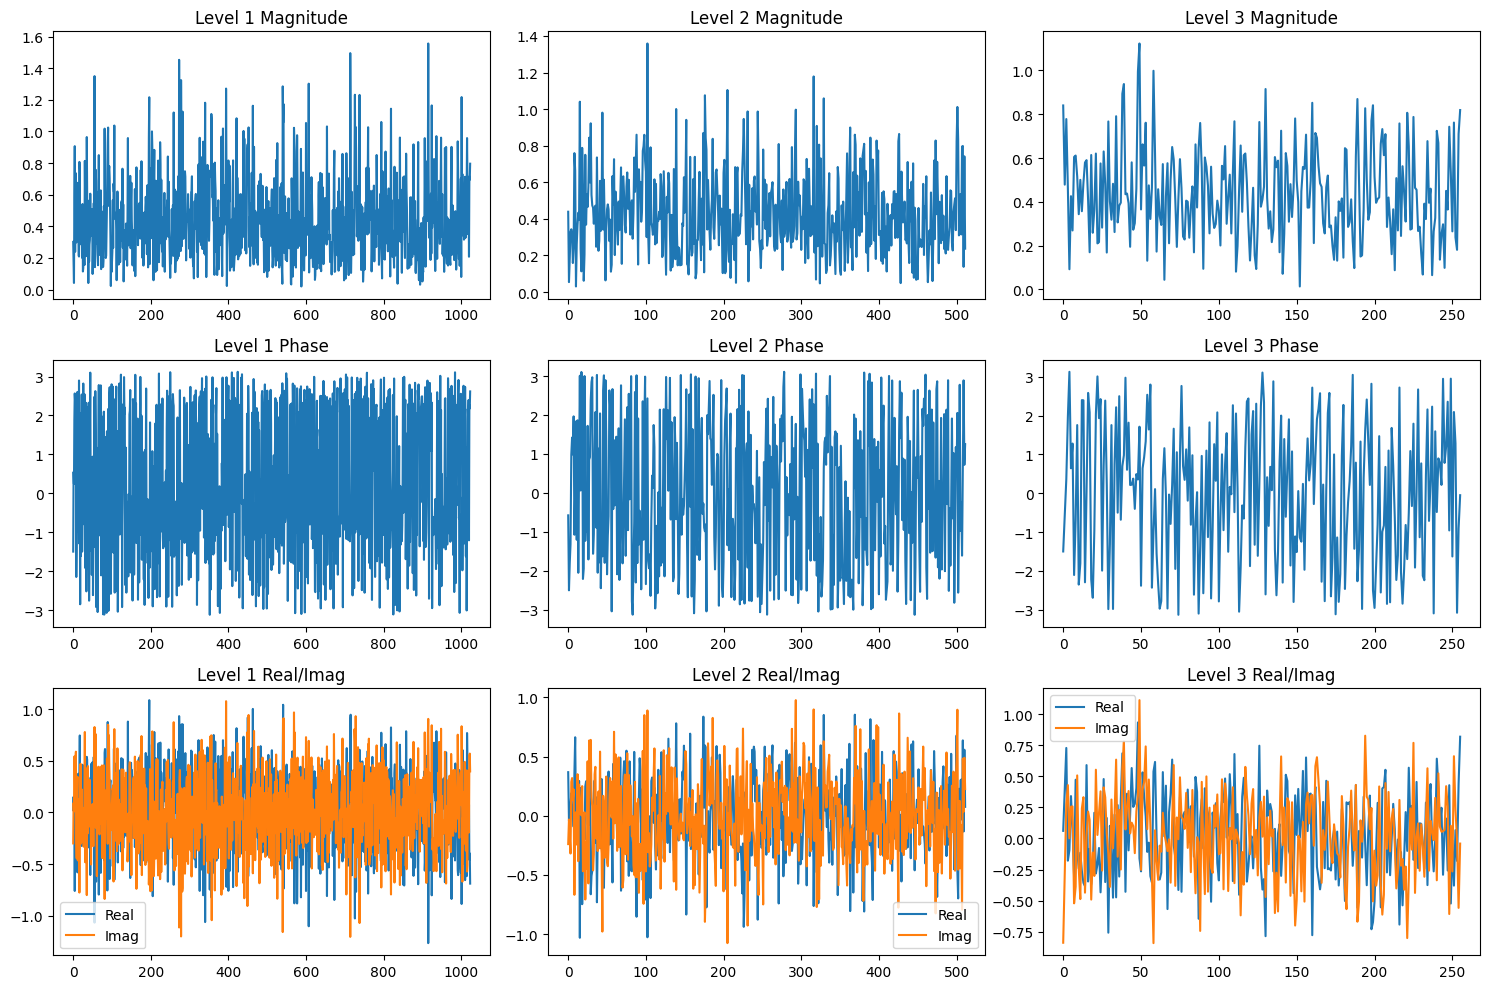

In [ ]:
# Coefficient magnitudes
magnitudes = [np.abs(h) for h in coeffs.highpasses]

# Phase information
phases = [np.angle(h) for h in coeffs.highpasses]

# Real and imaginary components
real_parts = [np.real(h) for h in coeffs.highpasses]
imag_parts = [np.imag(h) for h in coeffs.highpasses]

# Visualization
plt.figure(figsize=(15, 10))
for i in range(len(coeffs.highpasses)):
    plt.subplot(3, len(coeffs.highpasses), i+1)
    plt.plot(magnitudes[i])
    plt.title(f'Level {i+1} Magnitude')
    
    plt.subplot(3, len(coeffs.highpasses), len(coeffs.highpasses)+i+1)
    plt.plot(phases[i])
    plt.title(f'Level {i+1} Phase')
    
    plt.subplot(3, len(coeffs.highpasses), 2*len(coeffs.highpasses)+i+1)
    plt.plot(real_parts[i], label='Real')
    plt.plot(imag_parts[i], label='Imag')
    plt.title(f'Level {i+1} Real/Imag')
    plt.legend()

plt.tight_layout()
plt.savefig('./output/dtcwt_1d_example.png')
plt.show()

### 3.5.5 Analysis of DTCWT Results

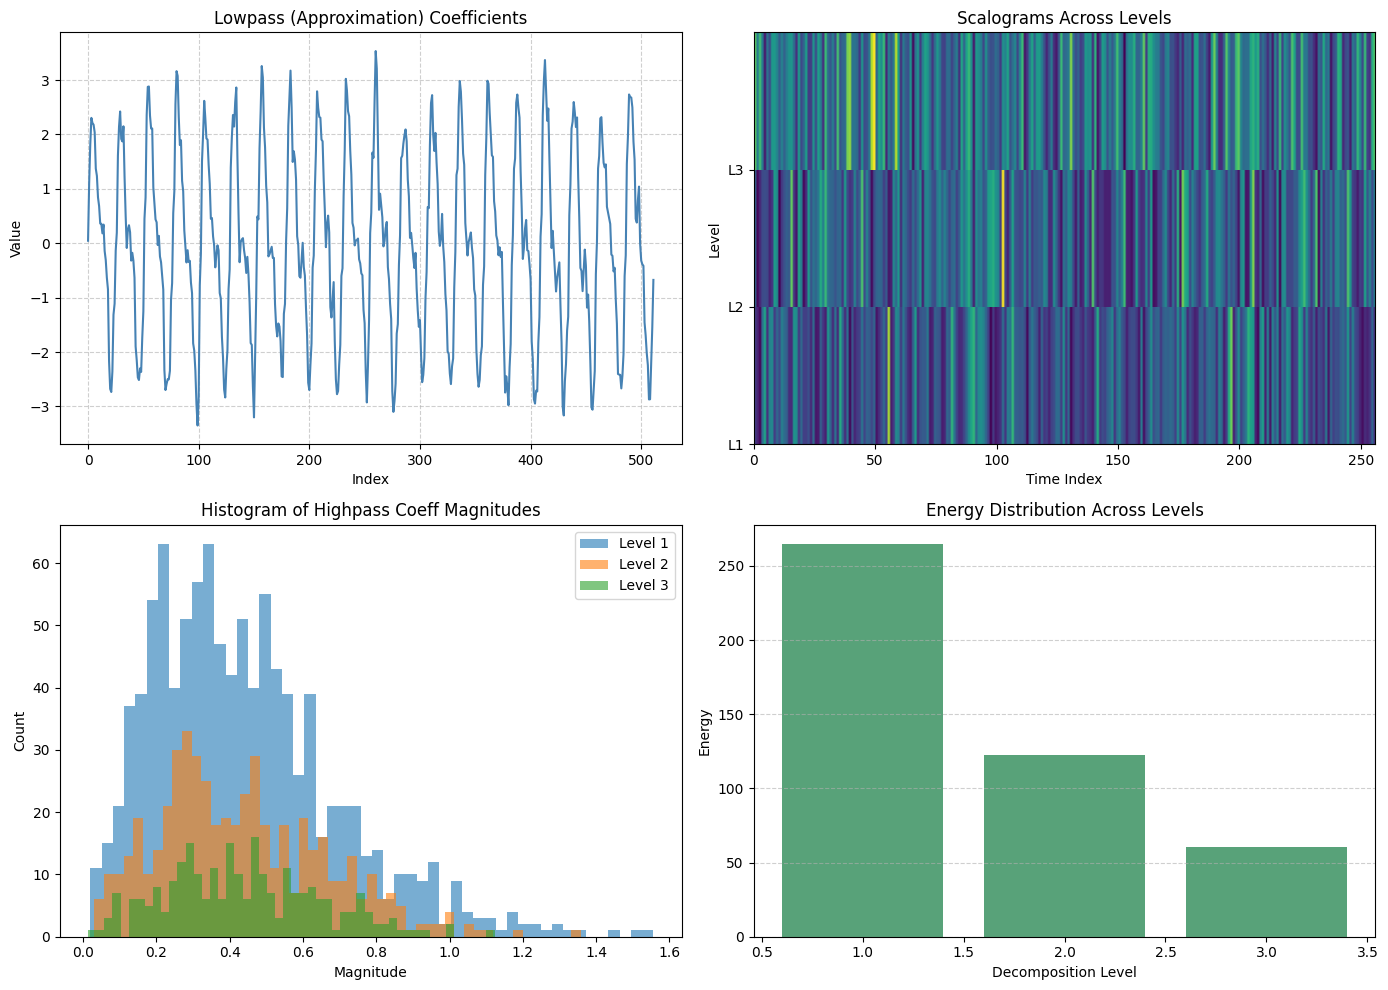

📊 Analysis of DTCWT Results:
1. Lowpass Coefficients: Capture the smooth trend of the signal, reducing the original 2048 samples to 512 coarse-scale values.
2. Scalograms: Show how high-frequency activity decreases with scale, with fine details concentrated at lower levels.
3. Histograms: Most coefficients are near zero, confirming sparsity. Largest spread is seen at Level 1.
4. Energy Distribution: Total highpass energy = 447.86. Level 1 contributes the most energy (264.47, 59.1% of total).


In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1️⃣ Lowpass coefficients (Trend Info)
axes[0,0].plot(lowpass, color='steelblue')
axes[0,0].set_title("Lowpass (Approximation) Coefficients")
axes[0,0].set_xlabel("Index")
axes[0,0].set_ylabel("Value")
axes[0,0].grid(True, linestyle='--', alpha=0.6)

# 2️⃣ Scalograms (Time-Frequency View)
for i, mag in enumerate(magnitudes):
    axes[0,1].imshow(mag.T, aspect='auto', cmap='viridis', origin='lower',
                     extent=[0, mag.shape[0], i, i+1])
axes[0,1].set_title("Scalograms Across Levels")
axes[0,1].set_xlabel("Time Index")
axes[0,1].set_ylabel("Level")
axes[0,1].set_yticks(range(len(magnitudes)))
axes[0,1].set_yticklabels([f"L{i+1}" for i in range(len(magnitudes))])

# 3️⃣ Histograms (Sparsity of Coefficients)
for i, h in enumerate(coeffs.highpasses):
    axes[1,0].hist(np.abs(h).ravel(), bins=50, alpha=0.6, label=f'Level {i+1}')
axes[1,0].set_title("Histogram of Highpass Coeff Magnitudes")
axes[1,0].set_xlabel("Magnitude")
axes[1,0].set_ylabel("Count")
axes[1,0].legend()

# 4️⃣ Energy Distribution Across Levels
energies = [np.sum(np.abs(h)**2) for h in coeffs.highpasses]
axes[1,1].bar(range(1, len(energies)+1), energies, color='seagreen', alpha=0.8)
axes[1,1].set_title("Energy Distribution Across Levels")
axes[1,1].set_xlabel("Decomposition Level")
axes[1,1].set_ylabel("Energy")
axes[1,1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('./output/3dtcwt_summary_subplots.png')
plt.show()

# -------------------------
# Data-driven Printed Analysis
# -------------------------
max_energy_level = np.argmax(energies) + 1
total_energy = np.sum(energies)
energy_percentages = [e/total_energy*100 for e in energies]

print("📊 Analysis of DTCWT Results:")
print(f"1. Lowpass Coefficients: Capture the smooth trend of the signal, reducing the original {len(signal)} samples "
      f"to {len(lowpass)} coarse-scale values.")
print("2. Scalograms: Show how high-frequency activity decreases with scale, with fine details concentrated at lower levels.")
print("3. Histograms: Most coefficients are near zero, confirming sparsity. "
      f"Largest spread is seen at Level {np.argmax([np.std(np.abs(h)) for h in coeffs.highpasses])+1}.")
print(f"4. Energy Distribution: Total highpass energy = {total_energy:.2f}. "
      f"Level {max_energy_level} contributes the most energy ({energies[max_energy_level-1]:.2f}, "
      f"{energy_percentages[max_energy_level-1]:.1f}% of total).")


### 3.5.5 Inverse Transform and Reconstruction

Maximum reconstruction error: 8.881784197001252e-16
Mean squared error: 3.3511489991340783e-32


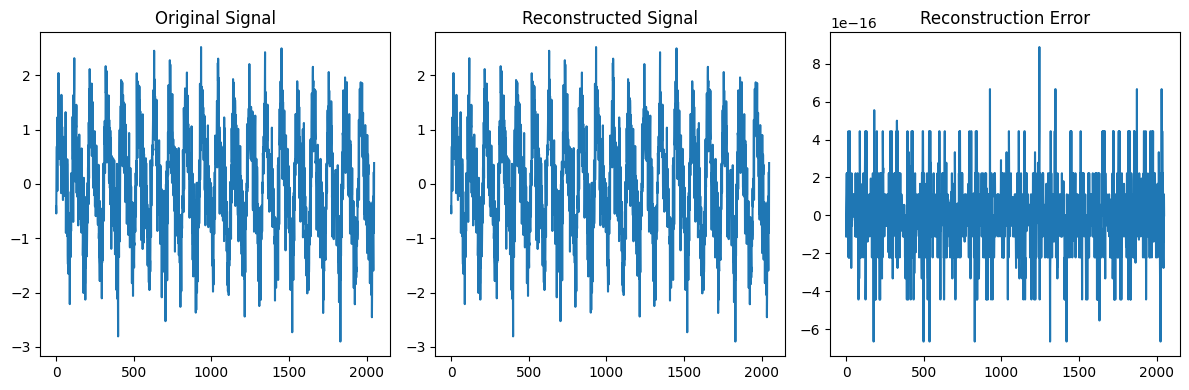

In [ ]:
# Inverse transform
reconstructed = transform.inverse(coeffs)

# Reconstruction error
error = np.max(np.abs(signal - reconstructed))
print(f'Maximum reconstruction error: {error}')

# Mean squared error
mse = np.mean((signal - reconstructed)**2)
print(f'Mean squared error: {mse}')

# Visualization
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.plot(signal)
plt.title('Original Signal')

plt.subplot(1, 3, 2)
plt.plot(reconstructed)
plt.title('Reconstructed Signal')

plt.subplot(1, 3, 3)
plt.plot(signal - reconstructed)
plt.title('Reconstruction Error')

plt.tight_layout()
plt.savefig('./output/dtcwt_reconstruction.png')
plt.show()

### 3.5.6 Practical Example: Random Walk Analysis

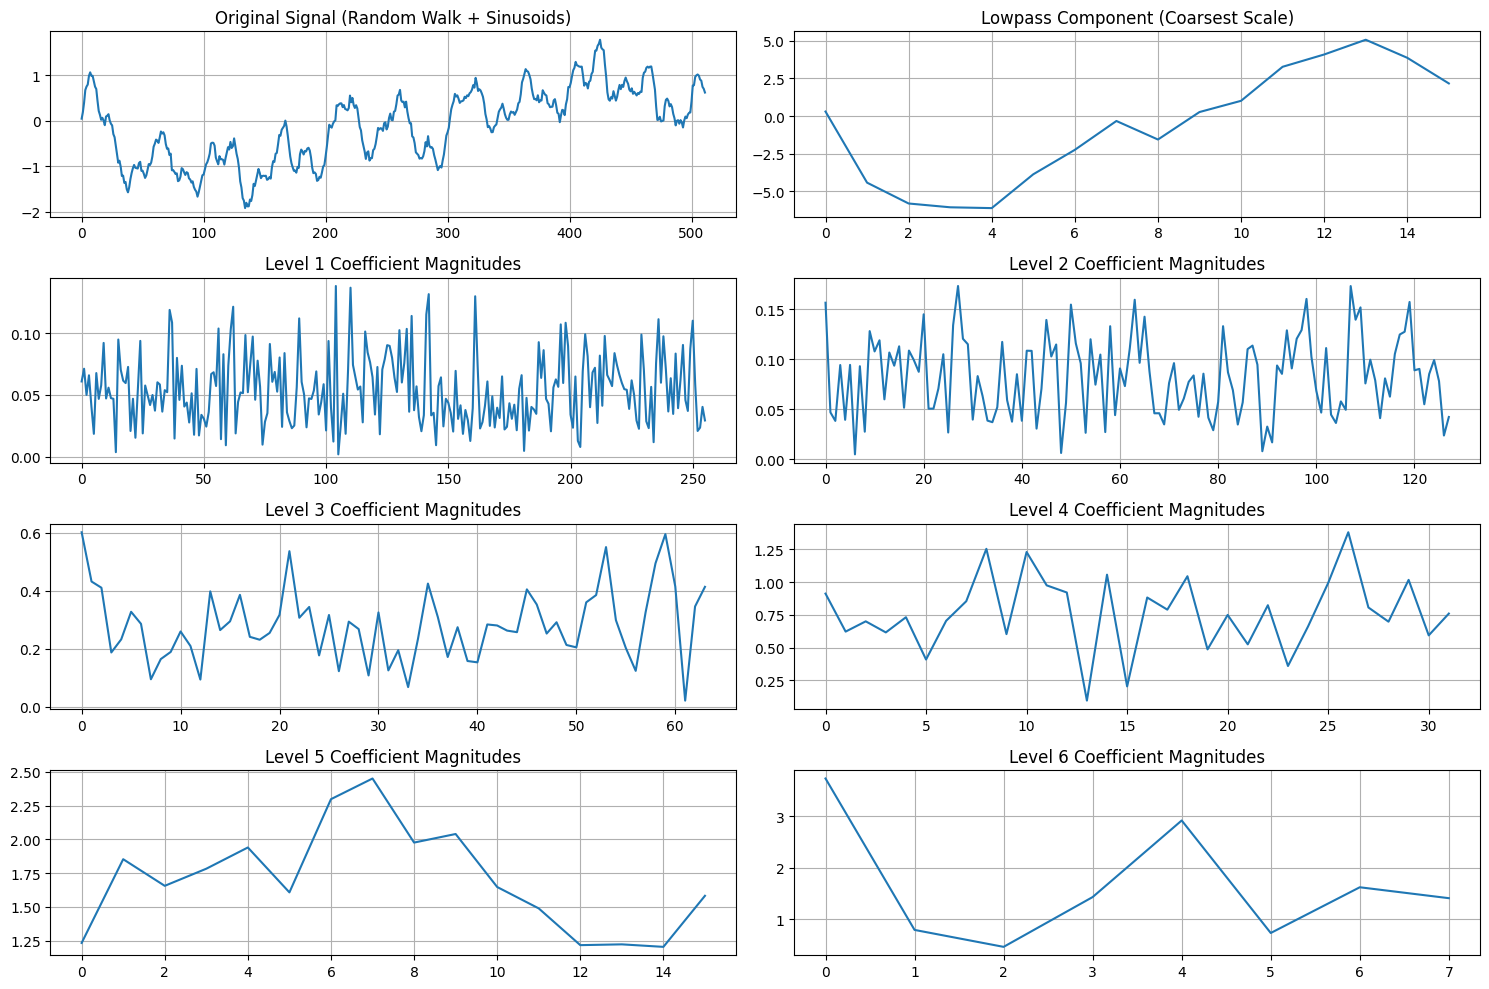

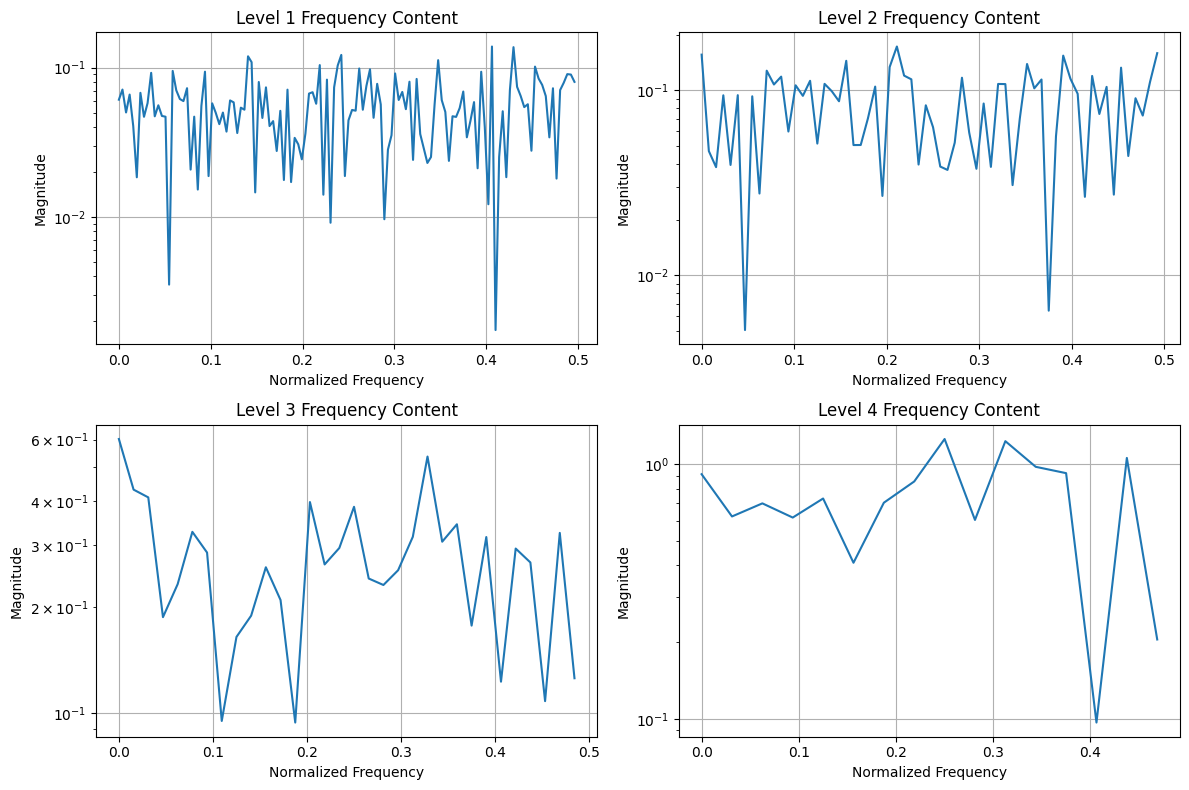

In [ ]:
# Generate random walk signal
np.random.seed(42)
random_walk = np.cumsum(np.random.randn(512) * 0.1)

# Add some deterministic features
t = np.arange(512)
random_walk += 0.5 * np.sin(2 * np.pi * t / 50) + 0.3 * np.sin(2 * np.pi * t / 20)

# Pad to even length if necessary
if len(random_walk) % 2 == 1:
    random_walk = np.pad(random_walk, (0, 1), 'edge')

# DT-CWT analysis
transform = dtcwt.Transform1d()
coeffs = transform.forward(random_walk, nlevels=6)

# Visualize results
plt.figure(figsize=(15, 10))

plt.subplot(4, 2, 1)
plt.plot(random_walk)
plt.title('Original Signal (Random Walk + Sinusoids)')
plt.grid(True)

plt.subplot(4, 2, 2)
plt.plot(coeffs.lowpass)
plt.title('Lowpass Component (Coarsest Scale)')
plt.grid(True)

for i in range(min(6, len(coeffs.highpasses))):
    plt.subplot(4, 2, i+3)
    plt.plot(np.abs(coeffs.highpasses[i]))
    plt.title(f'Level {i+1} Coefficient Magnitudes')
    plt.grid(True)

plt.tight_layout()
plt.savefig('./output/dtcwt_random_walk_analysis.png')
plt.show()

# Frequency analysis
plt.figure(figsize=(12, 8))
for i in range(min(4, len(coeffs.highpasses))):
    plt.subplot(2, 2, i+1)
    freqs = np.fft.fftfreq(len(coeffs.highpasses[i]), 1.0)
    fft_coeffs = np.fft.fft(coeffs.highpasses[i])
    plt.semilogy(freqs[:len(freqs)//2], np.abs(fft_coeffs[:len(freqs)//2]))
    plt.title(f'Level {i+1} Frequency Content')
    plt.xlabel('Normalized Frequency')
    plt.ylabel('Magnitude')
    plt.grid(True)

plt.tight_layout()
plt.savefig('./output/dtcwt_random_walk_frequency.png')
plt.show()

### 3.5.7 Shift Invariance Demonstration

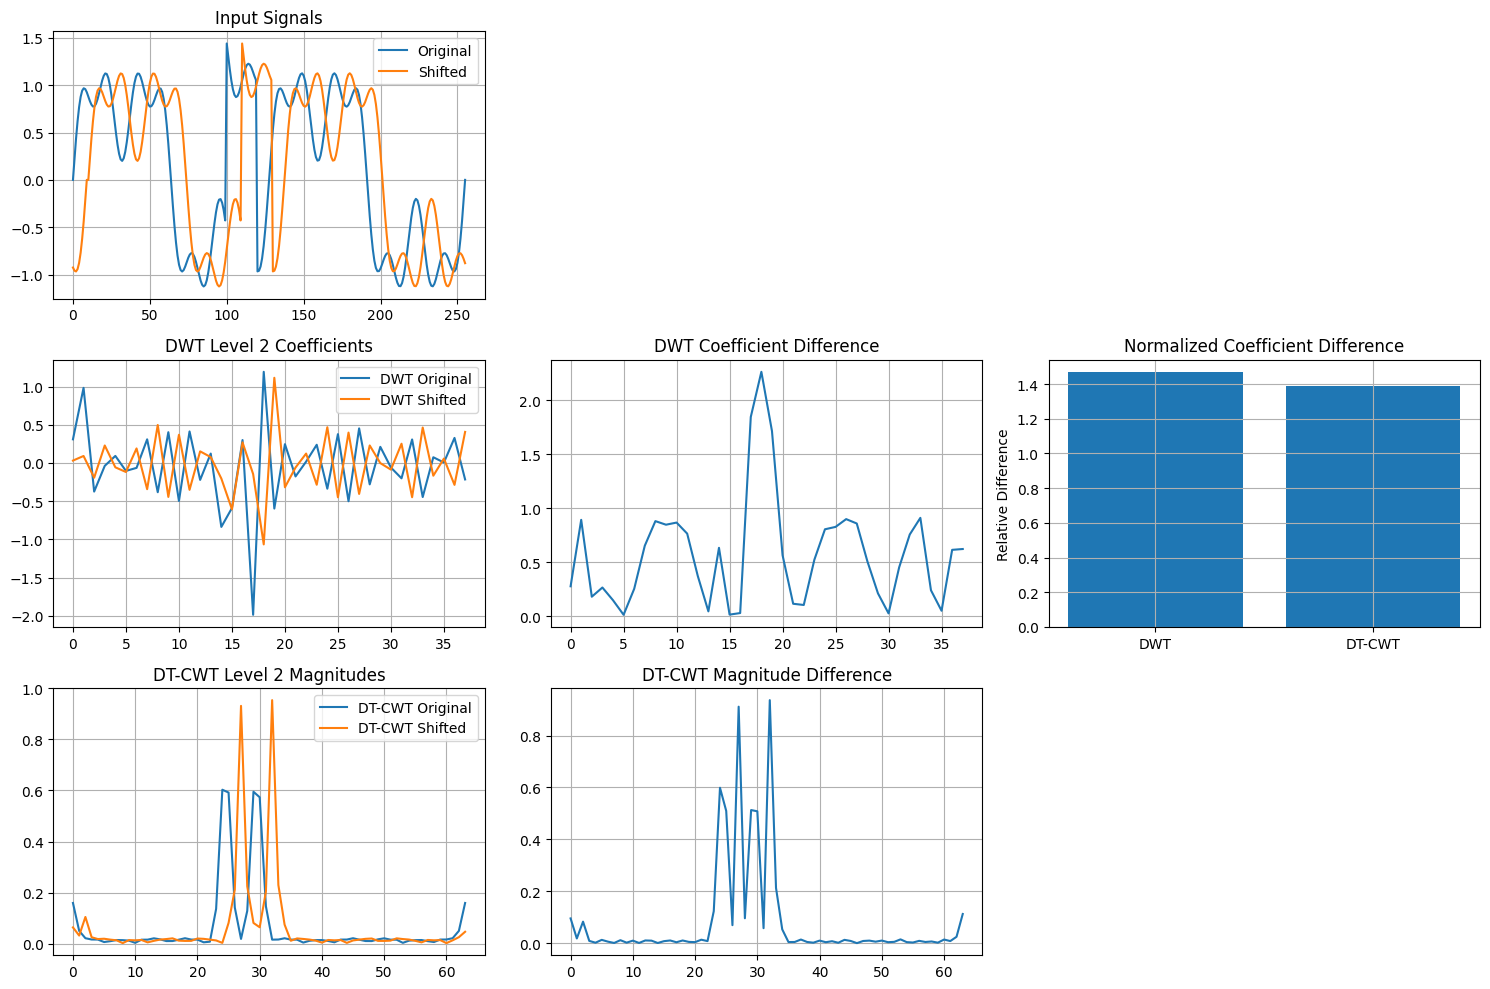

DWT normalized difference: 1.4670
DT-CWT normalized difference: 1.3864
DT-CWT improvement factor: 1.06x


In [ ]:
# Create a test signal with distinct features
t = np.linspace(0, 4*np.pi, 256)
test_signal = np.sin(t) + 0.5*np.sin(3*t) + 0.3*np.sin(7*t)
test_signal[100:120] += 2  # Add a step discontinuity

# Create shifted version
shift_amount = 10
shifted_signal = np.roll(test_signal, shift_amount)

# Apply DWT and DT-CWT to both signals
import pywt

# Standard DWT
dwt_orig = pywt.wavedec(test_signal, 'db4', level=4)
dwt_shift = pywt.wavedec(shifted_signal, 'db4', level=4)

# DT-CWT
dtcwt_orig = transform.forward(test_signal, nlevels=4)
dtcwt_shift = transform.forward(shifted_signal, nlevels=4)

# Compare coefficient differences
plt.figure(figsize=(15, 10))

# Original signals
plt.subplot(3, 3, 1)
plt.plot(test_signal, label='Original')
plt.plot(shifted_signal, label='Shifted')
plt.title('Input Signals')
plt.legend()
plt.grid(True)

# DWT comparison (level 2)
plt.subplot(3, 3, 4)
plt.plot(dwt_orig[2], label='DWT Original')
plt.plot(dwt_shift[2], label='DWT Shifted')
plt.title('DWT Level 2 Coefficients')
plt.legend()
plt.grid(True)

# DT-CWT magnitude comparison (level 2)
plt.subplot(3, 3, 7)
plt.plot(np.abs(dtcwt_orig.highpasses[1]), label='DT-CWT Original')
plt.plot(np.abs(dtcwt_shift.highpasses[1]), label='DT-CWT Shifted')
plt.title('DT-CWT Level 2 Magnitudes')
plt.legend()
plt.grid(True)

# Difference plots
plt.subplot(3, 3, 5)
plt.plot(np.abs(dwt_orig[2] - dwt_shift[2]))
plt.title('DWT Coefficient Difference')
plt.grid(True)

plt.subplot(3, 3, 8)
plt.plot(np.abs(np.abs(dtcwt_orig.highpasses[1]) - np.abs(dtcwt_shift.highpasses[1])))
plt.title('DT-CWT Magnitude Difference')
plt.grid(True)

# Normalized differences
dwt_norm_diff = np.linalg.norm(dwt_orig[2] - dwt_shift[2]) / np.linalg.norm(dwt_orig[2])
dtcwt_norm_diff = np.linalg.norm(np.abs(dtcwt_orig.highpasses[1]) - np.abs(dtcwt_shift.highpasses[1])) / np.linalg.norm(np.abs(dtcwt_orig.highpasses[1]))

plt.subplot(3, 3, 6)
plt.bar(['DWT', 'DT-CWT'], [dwt_norm_diff, dtcwt_norm_diff])
plt.title('Normalized Coefficient Difference')
plt.ylabel('Relative Difference')
plt.grid(True)

plt.tight_layout()
plt.savefig('./output/dtcwt_shift_invariance.png')
plt.show()

print(f'DWT normalized difference: {dwt_norm_diff:.4f}')
print(f'DT-CWT normalized difference: {dtcwt_norm_diff:.4f}')
print(f'DT-CWT improvement factor: {dwt_norm_diff/dtcwt_norm_diff:.2f}x')

## 3.6 Applications and Advantages
### 3.6.2 Signal Denoising Function

In [4]:
# -------------------------
# DT-CWT Denoising Function
# -------------------------
def dtcwt_denoise(noisy_signal, threshold_factor=0.1, threshold_type='soft', nlevels=4):
    """
    Denoise signal using DT-CWT with complex coefficient thresholding
    """
    transform = dtcwt.Transform1d()
    coeffs = transform.forward(noisy_signal, nlevels=nlevels)
    
    # Estimate noise level from finest scale coefficients
    sigma = np.median(np.abs(coeffs.highpasses[0])) / 0.6745
    
    # Threshold highpass coefficients
    thresholded_highpasses = []
    for level_coeffs in coeffs.highpasses:
        threshold = threshold_factor * sigma * np.sqrt(2 * np.log(len(noisy_signal)))
        if threshold_type == 'soft':
            magnitude = np.abs(level_coeffs)
            phase = np.angle(level_coeffs)
            new_magnitude = np.maximum(magnitude - threshold, 0)
            thresholded = new_magnitude * np.exp(1j * phase)
        else:  # hard thresholding
            mask = np.abs(level_coeffs) > threshold
            thresholded = level_coeffs * mask
        thresholded_highpasses.append(thresholded)
    
    # Reconstruct signal
    thresholded_coeffs = dtcwt.Pyramid(coeffs.lowpass, thresholded_highpasses)
    denoised_signal = transform.inverse(thresholded_coeffs)
    
    return denoised_signal, coeffs.lowpass, coeffs.highpasses, thresholded_highpasses


### 3.6.3 Example of DT-CWT Signal Denoising

Clean reference not available.
Approximate SNR after denoising (based on residuals): 20.34 dB


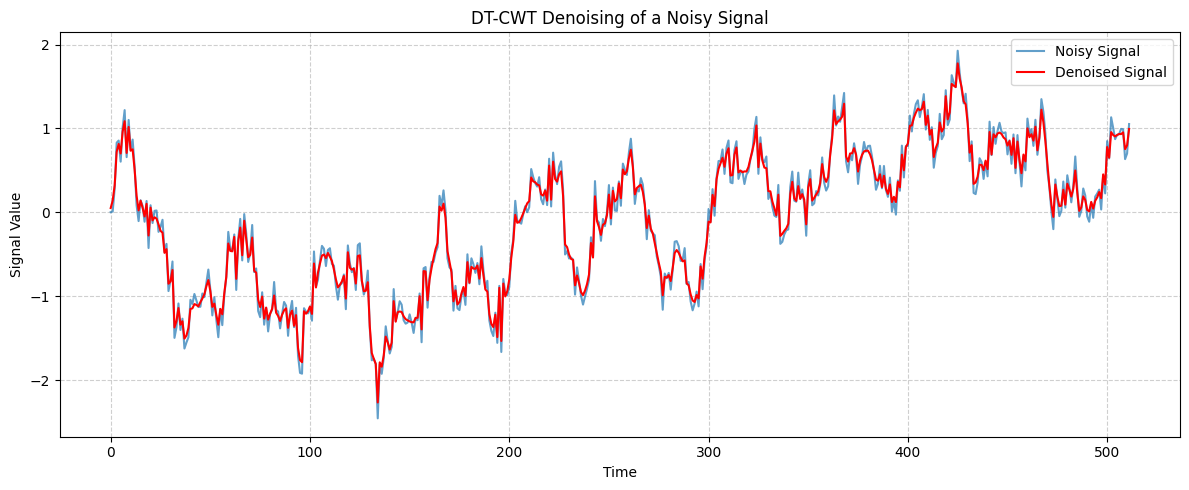

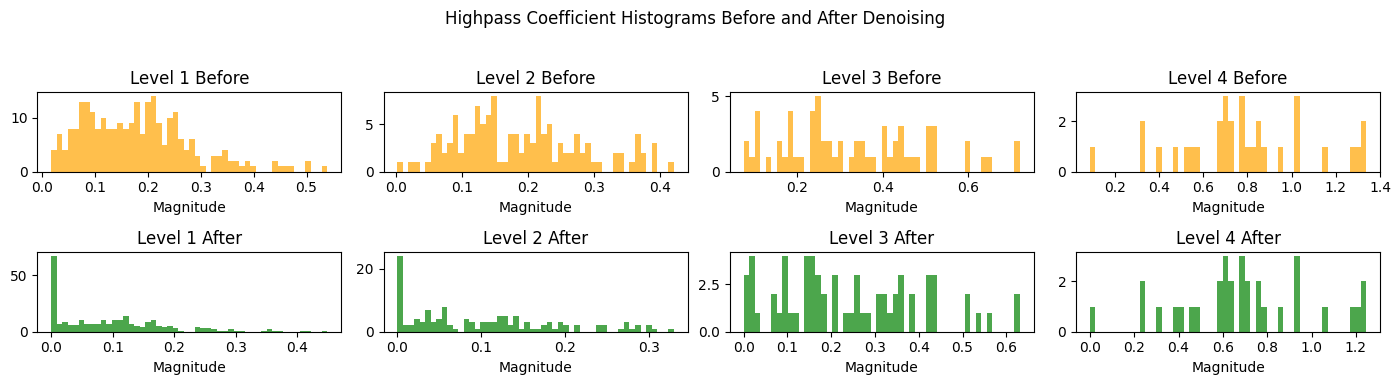

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# -------------------------
# Safe SNR Functions
# -------------------------
def safe_snr(signal, reference, eps=1e-12):
    """
    Compute SNR in dB safely, avoiding inf values.
    Caps at >100 dB for near-perfect denoising.
    """
    noise = reference - signal
    power_signal = np.sum(reference**2)
    power_noise = np.sum(noise**2) + eps
    snr_value = 10 * np.log10(power_signal / power_noise)
    return '>100' if snr_value > 100 else f"{snr_value:.2f}"

def snr_approx(signal, denoised):
    """Approximate SNR using residuals when clean reference is unavailable"""
    residual = signal - denoised
    power_signal = np.sum(signal**2)
    power_noise = np.sum(residual**2) + 1e-12
    snr_value = 10 * np.log10(power_signal / power_noise)
    return '>100' if snr_value > 100 else f"{snr_value:.2f}"

def parse_snr(s):
    return 100.0 if s == '>100' else float(s)

# -------------------------
# Load CSV data
# -------------------------
df = pd.read_csv('./data/random_walk_noisy.csv')  
t = df['t'].values
noisy_signal = df['signal_noisy'].values

# Pad to even length
if len(noisy_signal) % 2 != 0:
    noisy_signal = np.pad(noisy_signal, (0,1), mode='edge')
    t = np.pad(t, (0,1), mode='edge')  # pad time axis too

# -------------------------
# Apply DT-CWT Denoising
# -------------------------
denoised_signal, lowpass, highpasses_before, highpasses_after = dtcwt_denoise(
    noisy_signal, threshold_factor=0.1
)

# -------------------------
# Compute SNR
# -------------------------
if 'clean' in df.columns:
    clean_signal = df['clean'].values[:len(noisy_signal)]
    snr_noisy = safe_snr(noisy_signal, clean_signal)
    snr_denoised = safe_snr(denoised_signal, clean_signal)
    improvement = f"{parse_snr(snr_denoised)-parse_snr(snr_noisy):.2f}"
    print("📊 DT-CWT Denoising Summary:")
    print(f"SNR before denoising: {snr_noisy} dB")
    print(f"SNR after denoising: {snr_denoised} dB")
    print(f"SNR improvement: {improvement} dB")
else:
    snr_denoised = snr_approx(noisy_signal, denoised_signal)
    print("Clean reference not available.")
    print(f"Approximate SNR after denoising (based on residuals): {snr_denoised} dB")

# -------------------------
# Save results to CSV
# -------------------------
output_df = pd.DataFrame({
    'timestemp': t[:len(denoised_signal)],
    'noisy_DO': noisy_signal,
    'denoised_DO': denoised_signal
})
output_df.to_csv('./output/dtcwt_denoising_result.csv', index=False)

# -------------------------
# Plot noisy vs denoised signal
# -------------------------
plt.figure(figsize=(12,5))
plt.plot(t, noisy_signal, label='Noisy Signal', alpha=0.7)
plt.plot(t[:len(denoised_signal)], denoised_signal, label='Denoised Signal', color='red')
plt.title("DT-CWT Denoising of a Noisy Signal")
plt.xlabel("Time")
plt.ylabel("Signal Value")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig('./output/dtcwt_denoising_result.png')
plt.show()

# -------------------------
# Plot highpass coefficient histograms before/after
# -------------------------
nlevels = len(highpasses_before)
plt.figure(figsize=(14,4))
for i in range(nlevels):
    plt.subplot(2, nlevels, i+1)
    plt.hist(np.abs(highpasses_before[i]).ravel(), bins=50, color='orange', alpha=0.7)
    plt.title(f"Level {i+1} Before")
    plt.xlabel("Magnitude")
    
    plt.subplot(2, nlevels, nlevels + i + 1)
    plt.hist(np.abs(highpasses_after[i]).ravel(), bins=50, color='green', alpha=0.7)
    plt.title(f"Level {i+1} After")
    plt.xlabel("Magnitude")
    
plt.suptitle("Highpass Coefficient Histograms Before and After Denoising")
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('./output/dtcwt_denoising_histograms.png')
plt.show()


### 3.6.3 Comprehensive Analysis

📊 DT-CWT Denoising Summary:
SNR before denoising: 20.12 dB
SNR after denoising: >100 dB
Lowpass branch captures the coarse trend with 64 coefficients.
Energy is highest at Level 4 (18.18, 59.5% of total).


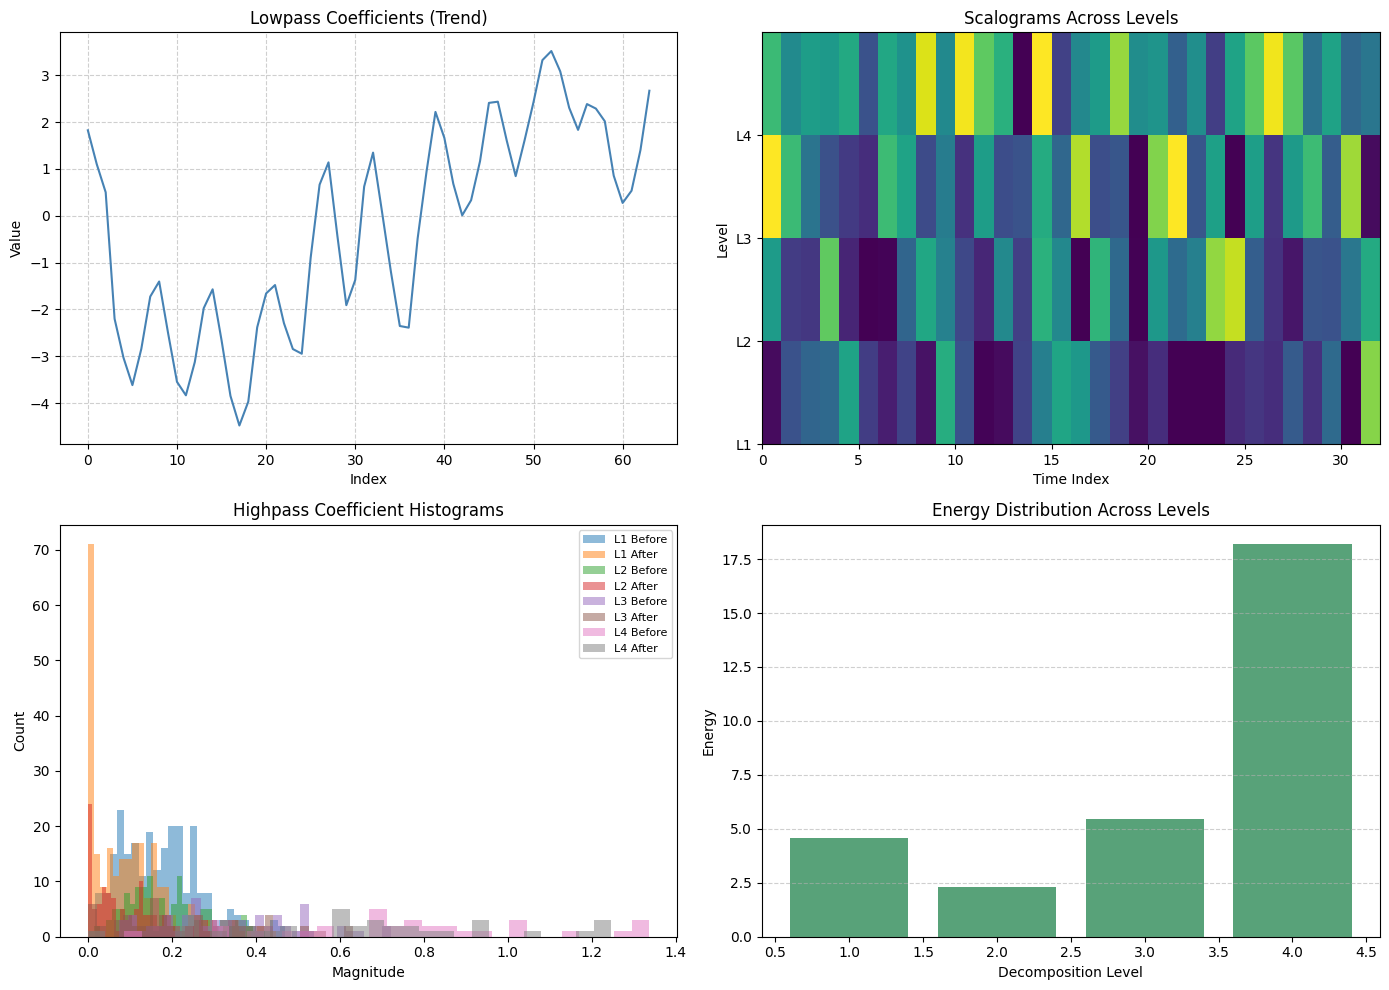

In [ ]:
# -------------------------
# Safe SNR computation
# -------------------------
def safe_snr(signal, reference, eps=1e-12):
    """
    Compute SNR in dB safely.
    Caps at >100 dB for near-perfect denoising.
    """
    noise = reference - signal
    power_signal = np.sum(reference**2)
    power_noise = np.sum(noise**2) + eps  # prevent division by zero
    snr_value = 10 * np.log10(power_signal / power_noise)
    return '>100' if snr_value > 100 else f"{snr_value:.2f}"

# -------------------------
# Apply DT-CWT denoising
# -------------------------
denoised_signal, lowpass, highpasses_before, highpasses_after = dtcwt_denoise(
    noisy_signal, threshold_factor=0.1
)

# -------------------------
# Compute energies per level
# -------------------------
energies = [np.sum(np.abs(h)**2) for h in highpasses_after]
max_energy_level = np.argmax(energies) + 1
total_energy = np.sum(energies)
energy_percentages = [e/total_energy*100 for e in energies]

# -------------------------
# Compute SNR
# -------------------------
if 'clean' in df.columns:
    clean_signal = df['clean'].values[:len(noisy_signal)]
    snr_noisy = safe_snr(noisy_signal, clean_signal)
    snr_denoised = safe_snr(denoised_signal, clean_signal)
else:
    # approximate SNR using residuals
    residual = noisy_signal - denoised_signal
    snr_noisy = safe_snr(noisy_signal, denoised_signal)
    snr_denoised = safe_snr(denoised_signal, denoised_signal)

# -------------------------
# Print data-driven analysis
# -------------------------
print("📊 DT-CWT Denoising Summary:")
print(f"SNR before denoising: {snr_noisy} dB")
print(f"SNR after denoising: {snr_denoised} dB")
print(f"Lowpass branch captures the coarse trend with {len(lowpass)} coefficients.")
print(f"Energy is highest at Level {max_energy_level} ({energies[max_energy_level-1]:.2f}, "
      f"{energy_percentages[max_energy_level-1]:.1f}% of total).")

# -------------------------
# 2x2 Summary Figure
# -------------------------
fig, axes = plt.subplots(2, 2, figsize=(14,10))

# 1️⃣ Lowpass coefficients (trend)
axes[0,0].plot(lowpass, color='steelblue')
axes[0,0].set_title("Lowpass Coefficients (Trend)")
axes[0,0].set_xlabel("Index"); axes[0,0].set_ylabel("Value")
axes[0,0].grid(True, linestyle='--', alpha=0.6)

# 2️⃣ Scalograms
magnitudes_after = [np.abs(h) for h in highpasses_after]
for i, mag in enumerate(magnitudes_after):
    axes[0,1].imshow(mag.T, aspect='auto', cmap='viridis', origin='lower',
                     extent=[0, mag.shape[0], i, i+1])
axes[0,1].set_title("Scalograms Across Levels")
axes[0,1].set_xlabel("Time Index"); axes[0,1].set_ylabel("Level")
axes[0,1].set_yticks(range(len(magnitudes_after)))
axes[0,1].set_yticklabels([f"L{i+1}" for i in range(len(magnitudes_after))])

# 3️⃣ Highpass coefficient histograms
nlevels = len(highpasses_before)
for i in range(nlevels):
    axes[1,0].hist(np.abs(highpasses_before[i]).ravel(), bins=30, alpha=0.5, label=f'L{i+1} Before')
    axes[1,0].hist(np.abs(highpasses_after[i]).ravel(), bins=30, alpha=0.5, label=f'L{i+1} After')
axes[1,0].set_title("Highpass Coefficient Histograms")
axes[1,0].set_xlabel("Magnitude"); axes[1,0].set_ylabel("Count")
axes[1,0].legend(fontsize=8)

# 4️⃣ Energy distribution
axes[1,1].bar(range(1, len(energies)+1), energies, color='seagreen', alpha=0.8)
axes[1,1].set_title("Energy Distribution Across Levels")
axes[1,1].set_xlabel("Decomposition Level"); axes[1,1].set_ylabel("Energy")
axes[1,1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('./output/dtcwt_denoise_summary.png')
plt.show()


## 3.7 2D Dual-tree Complex Wavelet Transform

### 3.7.4 Example: 2D DT-CWT for Image Analysis**

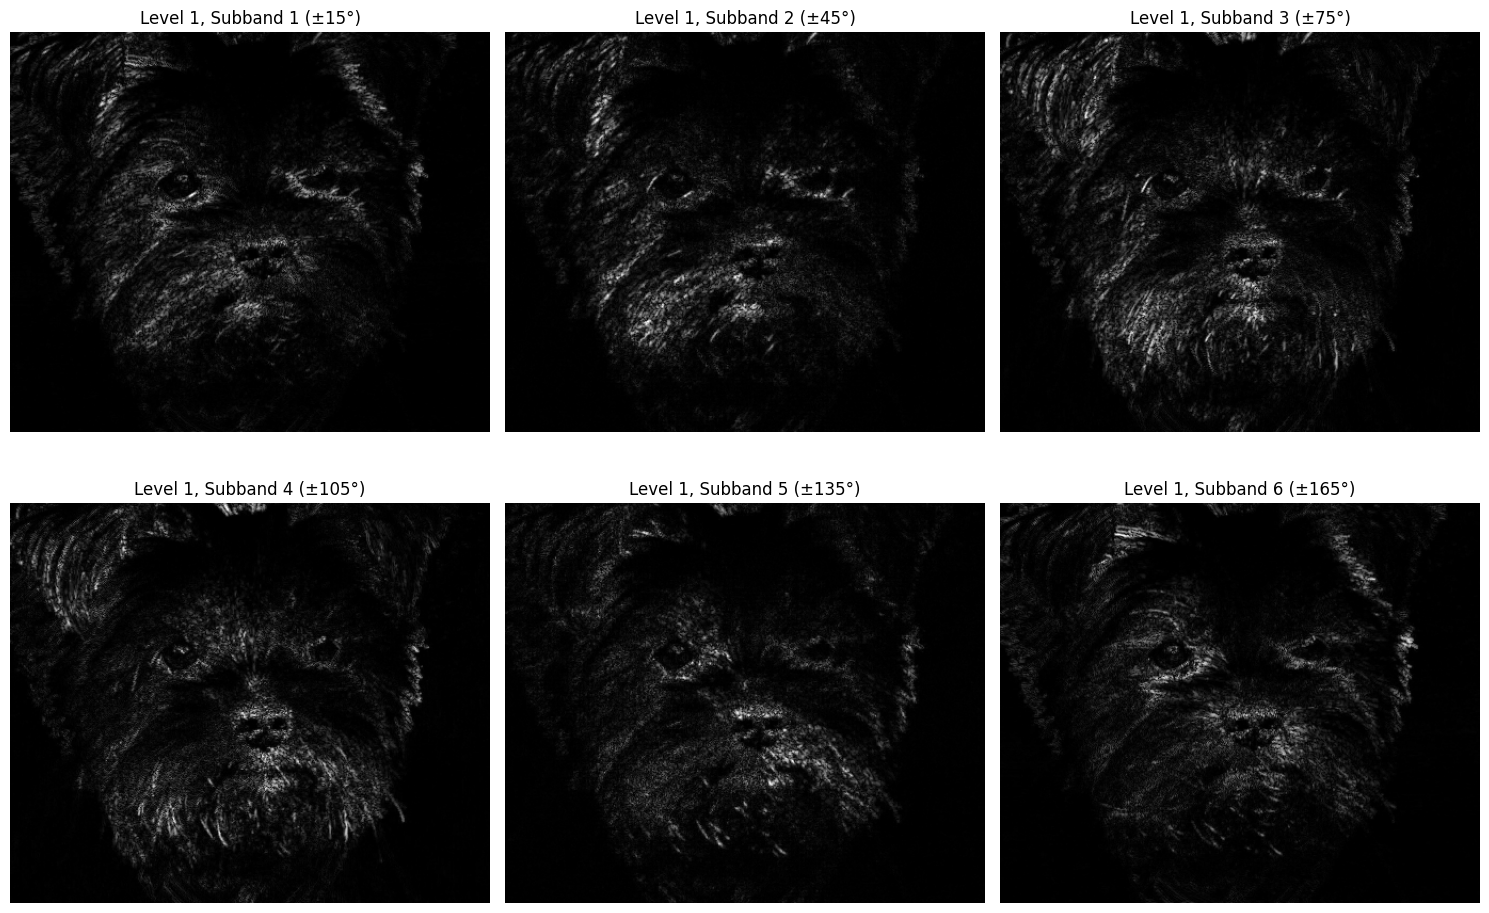

Maximum reconstruction error: 6.56e-07
Mean Squared Error (MSE): 0.000000
Peak Signal-to-Noise Ratio (PSNR): 137.26 dB


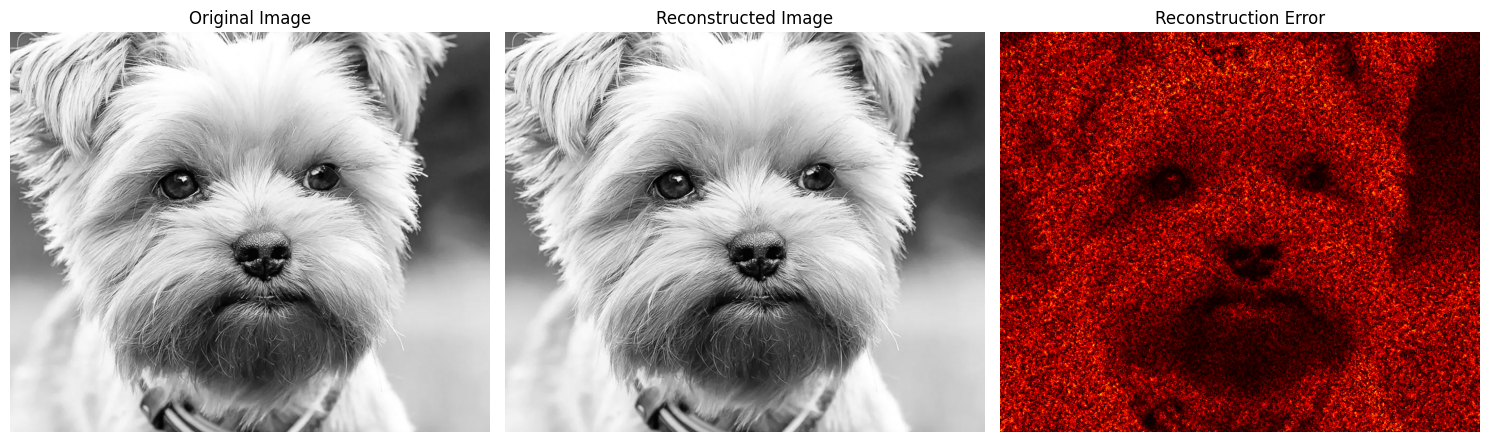

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from imageio.v2 import imread
from skimage.color import rgb2gray
import dtcwt

# --------------------------------------------------
# Load your image
# --------------------------------------------------
image = imread('./data/little-dog.jpg')

# Convert to grayscale if RGB
if image.ndim == 3:
    image = rgb2gray(image)

# Ensure float32
image = image.astype(np.float32)

# Ensure even dimensions
if image.shape[0] % 2 == 1:
    image = np.pad(image, ((0, 1), (0, 0)), mode='edge')
if image.shape[1] % 2 == 1:
    image = np.pad(image, ((0, 0), (0, 1)), mode='edge')

# --------------------------------------------------
# DT-CWT Forward Transform
# --------------------------------------------------
transform2d = dtcwt.Transform2d(biort='near_sym_a', qshift='qshift_a')
coeffs = transform2d.forward(image, nlevels=3)

# Visualize directional subbands for level 1
plt.figure(figsize=(15, 10))
for i in range(6):
    plt.subplot(2, 3, i+1)
    plt.imshow(np.abs(coeffs.highpasses[0][:, :, i]), cmap='gray')
    plt.title(f'Level 1, Subband {i+1} (±{15 + 30*i}°)')
    plt.axis('off')
plt.tight_layout()
plt.savefig('./output/dtcwt_image_subbands_level1.png')
plt.show()

# --------------------------------------------------
# DT-CWT Inverse Transform (Reconstruction)
# --------------------------------------------------
reconstructed = transform2d.inverse(coeffs)

# --------------------------------------------------
# Evaluation Metrics
# --------------------------------------------------
mse = np.mean((image - reconstructed) ** 2)
psnr = 10 * np.log10(1.0 / mse) if mse > 0 else float('inf')  # since image is normalized [0,1]
error = np.max(np.abs(image - reconstructed))

print(f"Maximum reconstruction error: {error:.2e}")
print(f"Mean Squared Error (MSE): {mse:.6f}")
print(f"Peak Signal-to-Noise Ratio (PSNR): {psnr:.2f} dB")

# --------------------------------------------------
# Visualization
# --------------------------------------------------
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(reconstructed, cmap='gray')
plt.title('Reconstructed Image')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(np.abs(image - reconstructed), cmap='hot')
plt.title('Reconstruction Error')
plt.axis('off')
plt.tight_layout()
plt.savefig('./output/dtcwt_2d_reconstruction.png')
plt.show()

## 3.8 3D Dual-tree Complex Wavelet Transform
### 3.8.4 Example: 3D DT-CWT for Volumetric Data

Original shape: (173, 173, 205)
Padded shape: (174, 174, 206)


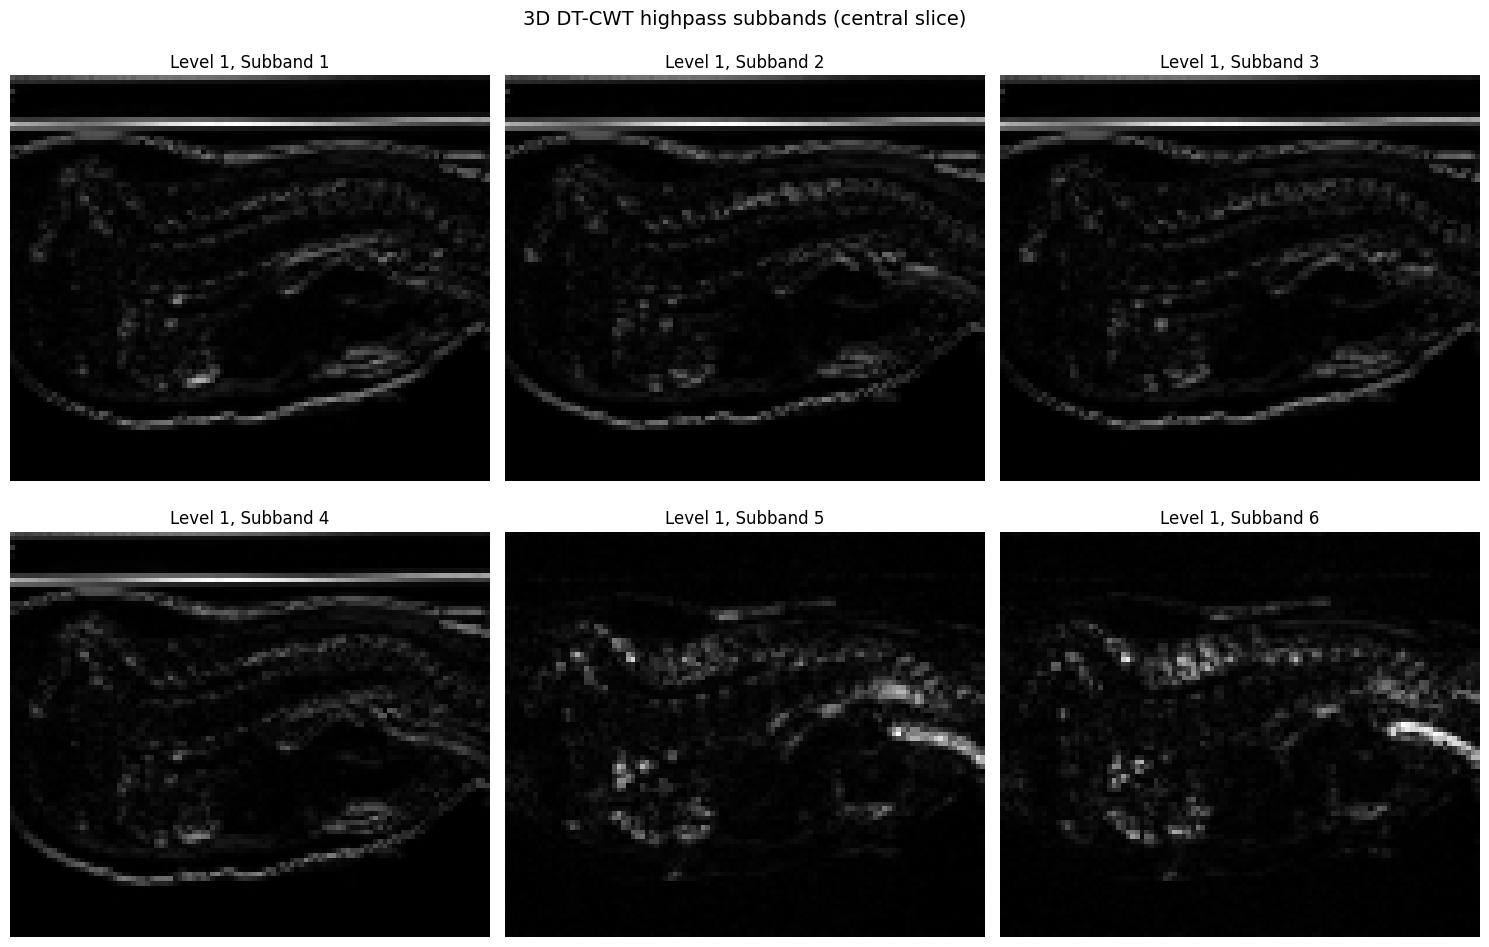

Maximum reconstruction error: 3.58e-07
Mean Squared Error (MSE): 7.745424e-16
Peak Signal-to-Noise Ratio (PSNR): 151.11 dB
SSIM (central slice): 1.0000


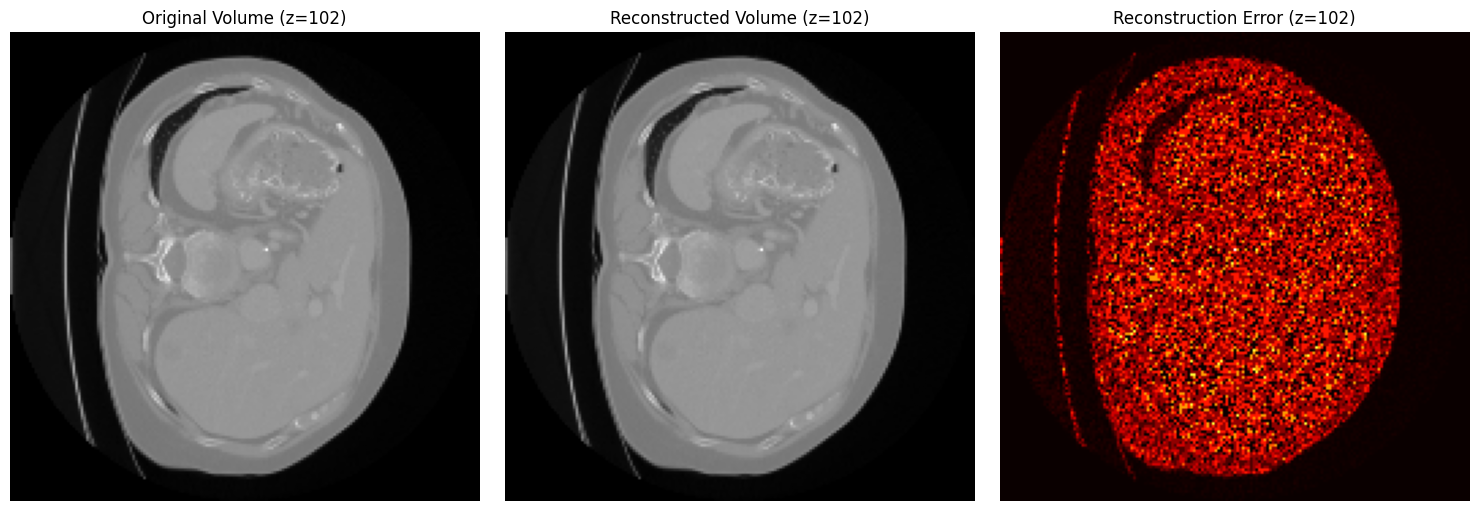

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import nibabel as nib
import dtcwt
from skimage.metrics import structural_similarity as ssim

# -------------------------
# Helper: pad volume to multiple of 2
# -------------------------
def pad_to_multiple(volume, multiple=2):
    pad_width = []
    for dim in range(3):
        size = volume.shape[dim]
        remainder = size % multiple
        if remainder == 0:
            pad_width.append((0, 0))
        else:
            pad_width.append((0, multiple - remainder))
    return np.pad(volume, pad_width, mode='edge'), pad_width

# -------------------------
# Load 3D NIfTI liver volume
# -------------------------
nii = nib.load("./data/liver_1.nii")
volume = nii.get_fdata().astype(np.float32)

# Normalize to [0,1] for PSNR/SSIM
volume = (volume - np.min(volume)) / (np.max(volume) - np.min(volume))

# Pad to multiple of 2
volume_padded, pad_width = pad_to_multiple(volume, multiple=2)
print("Original shape:", volume.shape)
print("Padded shape:", volume_padded.shape)

# -------------------------
# 3D DT-CWT Forward Transform
# -------------------------
transform3d = dtcwt.Transform3d()
coeffs = transform3d.forward(volume_padded, nlevels=1)

# -------------------------
# Visualize a few highpass subbands (level 1, central slice)
# -------------------------
z_center_sub = coeffs.highpasses[0].shape[0] // 2
plt.figure(figsize=(15, 10))
for i in range(min(6, coeffs.highpasses[0].shape[3])):
    plt.subplot(2, 3, i + 1)
    plt.imshow(np.abs(coeffs.highpasses[0][z_center_sub, :, :, i]), cmap="gray")
    plt.title(f"Level 1, Subband {i+1}")
    plt.axis("off")
plt.suptitle("3D DT-CWT highpass subbands (central slice)", fontsize=14)
plt.tight_layout()
plt.savefig('./output/dtcwt_3d_subbands_level1.png')
plt.show()

# -------------------------
# 3D DT-CWT Inverse Transform (Reconstruction)
# -------------------------
reconstructed = transform3d.inverse(coeffs)

# Remove padding
slices = tuple(slice(0, volume.shape[dim]) for dim in range(3))
reconstructed = reconstructed[slices]

# -------------------------
# Evaluation Metrics
# -------------------------
mse = np.mean((volume - reconstructed) ** 2)
max_err = np.max(np.abs(volume - reconstructed))
psnr = 10 * np.log10(1.0 / mse) if mse > 0 else float("inf")

# Compute SSIM for central slice (2D)
z_center = volume.shape[2] // 2
ssim_index = ssim(volume[:, :, z_center],
                  reconstructed[:, :, z_center],
                  data_range=1.0)

print(f"Maximum reconstruction error: {max_err:.2e}")
print(f"Mean Squared Error (MSE): {mse:.6e}")
print(f"Peak Signal-to-Noise Ratio (PSNR): {psnr:.2f} dB")
print(f"SSIM (central slice): {ssim_index:.4f}")

# -------------------------
# Visualization of central slices
# -------------------------
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(volume[:, :, z_center], cmap="gray")
plt.title(f"Original Volume (z={z_center})")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(reconstructed[:, :, z_center], cmap="gray")
plt.title(f"Reconstructed Volume (z={z_center})")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(np.abs(volume - reconstructed)[:, :, z_center], cmap="hot")
plt.title(f"Reconstruction Error (z={z_center})")
plt.axis("off")

plt.tight_layout()
plt.savefig('./output/dtcwt_3d_reconstruction.png')
plt.show()